# Task 1: Data Cleaning & Preprocessing

## AI & ML Internship

### Objective
To learn how to clean and prepare raw data for
machine learning by handling missing values,
encoding categorical variables, scaling numerical
features, and detecting outliers.

### Dataset
Titanic Dataset


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [28]:
from google.colab import files
uploaded=files.upload()

Saving Titanic-Dataset.csv to Titanic-Dataset (1).csv


In [32]:
df = pd.read_csv('Titanic-Dataset.csv')
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [33]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 891
Number of columns: 12


In [34]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [35]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [36]:
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_data = pd.DataFrame({
    'Missing Values': df.isnull().sum(),
    'Percentage': missing_percentage
})

print(missing_data)

             Missing Values  Percentage
PassengerId               0    0.000000
Survived                  0    0.000000
Pclass                    0    0.000000
Name                      0    0.000000
Sex                       0    0.000000
Age                     177   19.865320
SibSp                     0    0.000000
Parch                     0    0.000000
Ticket                    0    0.000000
Fare                      0    0.000000
Cabin                   687   77.104377
Embarked                  2    0.224467


In [37]:
df['Age']=df['Age'].fillna(df['Age'].median())
df['Embarked']=df['Embarked'].fillna(df['Embarked'].mode()[0])
df.drop('Cabin', axis=1 , inplace=True)

In [38]:
print(df.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [39]:
print("Total missing values:", df.isnull().sum().sum())
print("Updated dataset shape:", df.shape)

Total missing values: 0
Updated dataset shape: (891, 11)


In [40]:
df['Sex'] = df['Sex'].map({
    'male': 0,
    'female': 1
})
print(df['Sex'].head())

0    0
1    1
2    1
3    1
4    0
Name: Sex, dtype: int64


In [41]:
embarked_encoded = pd.get_dummies(
    df['Embarked'],
    prefix='Embarked',
    dtype=int
)

df = pd.concat(
    [df.drop('Embarked', axis=1), embarked_encoded],
    axis=1
)

In [42]:
print(df.dtypes)
print("\nUpdated dataset:")
df.head()

PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex              int64
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Embarked_C       int64
Embarked_Q       int64
Embarked_S       int64
dtype: object

Updated dataset:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked_C,Embarked_Q,Embarked_S
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,0,0,1
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,1,0,0
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,0,0,1
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,0,0,1
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,0,0,1


In [43]:
numerical_columns = ['Age', 'Fare', 'SibSp', 'Parch']

print(df[numerical_columns].describe())

              Age        Fare       SibSp       Parch
count  891.000000  891.000000  891.000000  891.000000
mean    29.361582   32.204208    0.523008    0.381594
std     13.019697   49.693429    1.102743    0.806057
min      0.420000    0.000000    0.000000    0.000000
25%     22.000000    7.910400    0.000000    0.000000
50%     28.000000   14.454200    0.000000    0.000000
75%     35.000000   31.000000    1.000000    0.000000
max     80.000000  512.329200    8.000000    6.000000


In [44]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df_normalized=df.copy()

df_normalized[numerical_columns] = scaler.fit_transform(
     df_normalized[numerical_columns]
)

df_normalized[numerical_columns].head()

,Age,Fare,SibSp,Parch
0,0.271174,0.014151,0.125,0.0
1,0.472229,0.139136,0.125,0.0
2,0.321438,0.015469,0.000,0.0
3,0.434531,0.103644,0.125,0.0
4,0.434531,0.015713,0.000,0.0


In [45]:
print("Minimum values:")
print(df_normalized[numerical_columns].min())

print("\nMaximum values:")
print(df_normalized[numerical_columns].max())

Minimum values:
Age      0.0
Fare     0.0
SibSp    0.0
Parch    0.0
dtype: float64

Maximum values:
Age      1.0
Fare     1.0
SibSp    1.0
Parch    1.0
dtype: float64


In [46]:
from sklearn.preprocessing import StandardScaler

standard_scaler = StandardScaler()

df_standardized = df.copy()

df_standardized[numerical_columns] = standard_scaler.fit_transform(
    df_standardized[numerical_columns]
)

df_standardized[numerical_columns].head()

,Age,Fare,SibSp,Parch
0,-0.565736,-0.502445,0.432793,-0.473674
1,0.663861,0.786845,0.432793,-0.473674
2,-0.258337,-0.488854,-0.474545,-0.473674
3,0.433312,0.420730,0.432793,-0.473674
4,0.433312,-0.486337,-0.474545,-0.473674


In [47]:
print("Mean values:")
print(df_standardized[numerical_columns].mean())

print("\nStandard deviation:")
print(df_standardized[numerical_columns].std(ddof=0))

Mean values:
Age      2.272780e-16
Fare     3.987333e-18
SibSp    4.386066e-17
Parch    5.382900e-17
dtype: float64

Standard deviation:
Age      1.0
Fare     1.0
SibSp    1.0
Parch    1.0
dtype: float64


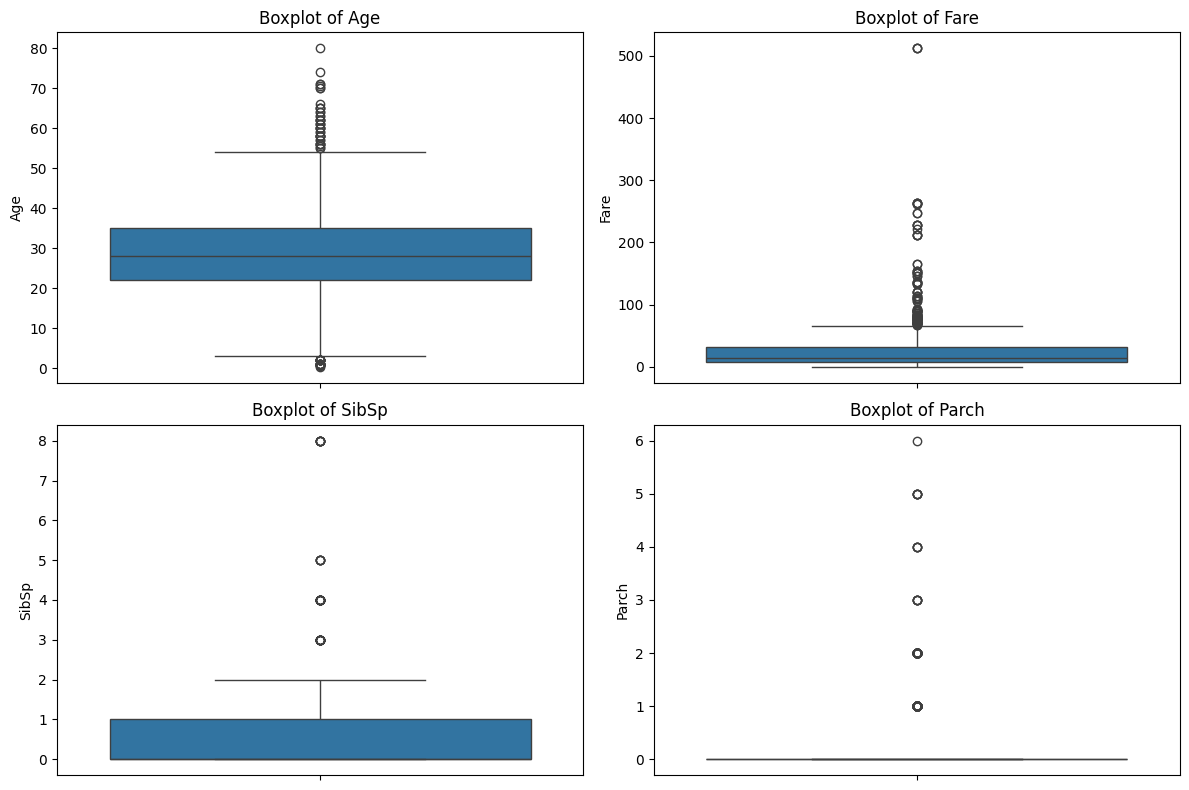

In [58]:
plt.figure(figsize=(12, 8))

for i, column in enumerate(numerical_columns, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[column])
    plt.title(f'Boxplot of {column}')

plt.tight_layout()
plt.savefig('outliers_after.png', dpi=300, bbox_inches='tight')
plt.show()

In [49]:
for column in ['Age', 'Fare']:

    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    print(f"\n{column}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))


Age
Lower Bound: 2.5
Upper Bound: 54.5
Number of Outliers: 66

Fare
Lower Bound: -26.724
Upper Bound: 65.6344
Number of Outliers: 116


In [51]:
df_cleaned = df.copy()

for column in ['Age', 'Fare']:

    Q1 = df_cleaned[column].quantile(0.25)
    Q3 = df_cleaned[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_cleaned[column] = df_cleaned[column].clip(
        lower=lower_bound,
        upper=upper_bound
    )

print("Original shape:", df.shape)
print("Cleaned shape:", df_cleaned.shape)

Original shape: (891, 13)
Cleaned shape: (891, 13)


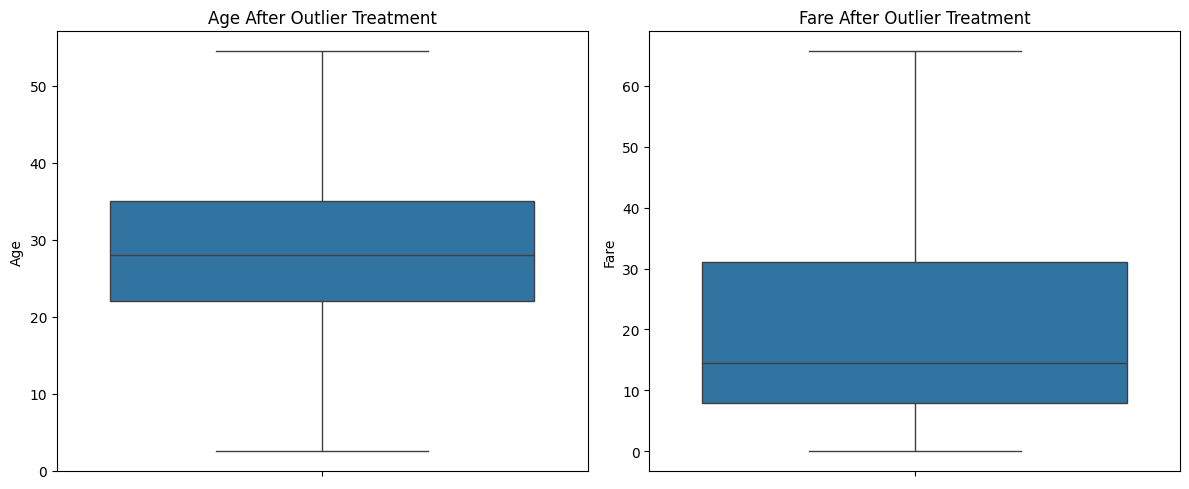

In [56]:
plt.figure(figsize=(12, 5))

for i, column in enumerate(['Age', 'Fare'], 1):
    plt.subplot(1, 2, i)
    sns.boxplot(y=df_cleaned[column])
    plt.title(f'{column} After Outlier Treatment')

plt.tight_layout()
plt.savefig('outliers_after.png', dpi=300, bbox_inches='tight')
plt.show()

In [53]:
print("SibSp value counts:")
print(df['SibSp'].value_counts().sort_index())

print("\nParch value counts:")
print(df['Parch'].value_counts().sort_index())

SibSp value counts:
SibSp
0    608
1    209
2     28
3     16
4     18
5      5
8      7
Name: count, dtype: int64

Parch value counts:
Parch
0    678
1    118
2     80
3      5
4      4
5      5
6      1
Name: count, dtype: int64


In [54]:
df_cleaned.to_csv('titanic_cleaned.csv', index=False)
from google.colab import files
files.download('titanic_cleaned.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [59]:
files.download('outliers_before.png')
files.download('outliers_after.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>